<a href="https://colab.research.google.com/github/mjanakiramster/HMT-LACNN-ECG-Classification/blob/main/Diabetes_Classification_Full_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratory-Free Diabetes Classification under Leakage-Resistant Validation
### Complete analysis notebook for the revised manuscript (NHANES 2017–2018, Pima, Frankfurt audit)

This notebook reproduces **every table and figure** in the revised manuscript from the raw data files.

| Part | What it does |
|---|---|
| 1 | Setup and configuration |
| 2 | Build the NHANES 2017–2018 cohort from 15 CDC `.XPT` files (label: diagnosed **or** HbA1c ≥ 6.5 %) |
| 3 | Feature sets A–D and the Pima benchmark |
| 4 | Models: 3 single learners + 6 ensembles (hard / soft / weighted soft voting, conventional stacking, calibrated stacking, ARWE) |
| 5 | Leakage-resistant 5 × 5 repeated CV (all pre-processing refitted inside every inner and outer training fold) |
| 6 | Results tables with corrected 95 % CIs; best ensemble vs strongest single learner (corrected t-test + bootstrap) |
| 7 | Calibration (Brier, ECE, intercept, slope, plots), decision-curve analysis, risk thresholds |
| 8 | Robustness: rank stability, subgroups, survey-weighted AUC |
| 9 | Frankfurt Hospital file: duplicate and Pima-overlap audit; random vs de-duplicated vs grouped CV |
| 10 | Permutation importance |
| 11 | Save all results |

**Folder layout expected** (relative to this notebook in `code/`):
```
diabets1/
 ├── code/       <- this notebook
 ├── data/       nhanes_2017_2018/*.XPT, pima_diabetes.csv, frankfurt_diabetes.csv
 ├── results/    created automatically
 └── figures/    created automatically
```
**Run time** (5 repeats): about 60–90 min on a 4–8-core laptop; set `N_REPEATS = 1` for a quick test (about 5× faster). A GPU does not help.

In [1]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 23.4 MB/s  0:00:04


In [2]:
# On Google Colab, uncomment the next two lines first:
# !pip install -q catboost
# (then upload the data/ folder next to code/ or change DATA below)
import os, json, time, warnings, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize, minimize_scalar
warnings.filterwarnings("ignore")
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, StackingClassifier
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, StratifiedGroupKFold, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, roc_curve,
                             confusion_matrix, accuracy_score)
from sklearn.inspection import permutation_importance
from catboost import CatBoostClassifier

# ---------------- configuration ----------------
DATA     = "../data"
NHANES   = f"{DATA}/nhanes_2017_2018"
RESULTS  = "../results"
FIGURES  = "../figures"
N_REPEATS = 5          # 5 x 5-fold = 25 fits per model and dataset; use 1 for a quick test
SEED      = 42
for d in (NHANES, RESULTS, FIGURES): os.makedirs(d, exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Serif", "font.size": 8.5, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#a3a29c"})
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"
print("ready")

ready


## 2. Build the NHANES 2017–2018 cohort
Files are read from `data/nhanes_2017_2018/`; any missing file is downloaded from the CDC.
**Inclusion:** age ≥ 20, not pregnant, HbA1c measured, valid answer to DIQ010.
**Outcome:** diabetes = doctor-diagnosed (DIQ010 = 1) **or** HbA1c ≥ 6.5 %. HbA1c is never used as a predictor.

In [3]:
FILES = ["DEMO_J","BMX_J","BPX_J","BPQ_J","MCQ_J","PAQ_J","SMQ_J","SLQ_J","GHB_J","GLU_J","INS_J","HDL_J","TCHOL_J","DIQ_J"]
URLS = ["https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/{f}.xpt", "https://wwwn.cdc.gov/Nchs/Nhanes/2017-2018/{f}.XPT"]
def get(f):
    for n in (f + ".XPT", f + ".xpt"):
        if os.path.exists(f"{NHANES}/{n}"): return pd.read_sas(f"{NHANES}/{n}")
    for u in URLS:
        try: urllib.request.urlretrieve(u.format(f=f), f"{NHANES}/{f}.XPT"); return pd.read_sas(f"{NHANES}/{f}.XPT")
        except Exception: pass
    raise FileNotFoundError(f"{f}: put the file in {NHANES}")
raw = {f: get(f) for f in FILES}

d = raw["DEMO_J"][["SEQN","RIDAGEYR","RIAGENDR","RIDRETH3","INDFMPIR","RIDEXPRG","WTMEC2YR"]]
for f, c in [("BMX_J",["BMXBMI","BMXWAIST","BMXHT"]), ("BPX_J",[f"BPXSY{i}" for i in range(1,5)]+[f"BPXDI{i}" for i in range(1,5)]),
             ("BPQ_J",["BPQ020","BPQ080"]), ("MCQ_J",["MCQ300C"]), ("PAQ_J",["PAQ650","PAQ665","PAD680"]), ("SMQ_J",["SMQ020"]),
             ("SLQ_J",["SLD012"]), ("GHB_J",["LBXGH"]), ("GLU_J",["LBXGLU","WTSAF2YR"]), ("INS_J",["LBXIN"]),
             ("HDL_J",["LBDHDD"]), ("TCHOL_J",["LBXTC"]), ("DIQ_J",["DIQ010"])]:
    d = d.merge(raw[f][["SEQN"] + c], on="SEQN", how="left")
flow = {"All participants": len(d)}
d = d[d.RIDAGEYR >= 20];             flow["Adults >= 20 y"] = len(d)
d = d[d.RIDEXPRG != 1];              flow["Not pregnant"] = len(d)
d = d[d.LBXGH.notna()];              flow["HbA1c measured"] = len(d)
d = d[d.DIQ010.isin([1, 2, 3])].copy(); flow["Valid DIQ010 (analytic cohort)"] = len(d)
yn = lambda s: s.map({1: 1., 2: 0.})
nh = pd.DataFrame({"SEQN": d.SEQN, "Age": d.RIDAGEYR, "Male": (d.RIAGENDR == 1) * 1., "Ethnicity": d.RIDRETH3,
    "PovertyIncomeRatio": d.INDFMPIR, "BMI": d.BMXBMI, "Waist": d.BMXWAIST, "WaistHeightRatio": d.BMXWAIST / d.BMXHT,
    "SystolicBP": d[[f"BPXSY{i}" for i in range(1,5)]].mean(axis=1),
    "DiastolicBP": d[[f"BPXDI{i}" for i in range(1,5)]].replace(0, np.nan).mean(axis=1),
    "HypertensionHx": yn(d.BPQ020), "HighCholHx": yn(d.BPQ080), "FamilyHxDiabetes": yn(d.MCQ300C),
    "VigorousRecActivity": yn(d.PAQ650), "ModerateRecActivity": yn(d.PAQ665), "SedentaryMin": d.PAD680.where(d.PAD680 <= 1440),
    "EverSmoker": yn(d.SMQ020), "SleepHours": d.SLD012, "FastingGlucose": d.LBXGLU, "FastingInsulin": d.LBXIN,
    "HDL": d.LBDHDD, "TotalChol": d.LBXTC, "HbA1c": d.LBXGH, "DiagnosedDiabetes": (d.DIQ010 == 1) * 1.,
    "WTMEC2YR": d.WTMEC2YR, "WTSAF2YR": d.WTSAF2YR}).reset_index(drop=True)
nh["Diabetes"] = ((d.DIQ010.values == 1) | (d.LBXGH.values >= 6.5)).astype(int)
nh.to_csv(f"{DATA}/nhanes_2017_2018_diabetes.csv", index=False)
for k, v in flow.items(): print(f"{k:35s} {v:6,d}")
print(f"Diabetes: {nh.Diabetes.sum()} ({nh.Diabetes.mean():.1%});  survey-weighted prevalence {np.average(nh.Diabetes, weights=nh.WTMEC2YR):.1%}")

All participants                     9,254
Adults >= 20 y                       5,569
Not pregnant                         5,514
HbA1c measured                       4,971
Valid DIQ010 (analytic cohort)       4,967
Diabetes: 994 (20.0%);  survey-weighted prevalence 14.3%


## 3. Feature sets and the Pima benchmark

In [5]:
NONLAB = ["Age","Male","Ethnicity","PovertyIncomeRatio","BMI","Waist","WaistHeightRatio","SystolicBP","DiastolicBP","HypertensionHx",
          "HighCholHx","FamilyHxDiabetes","VigorousRecActivity","ModerateRecActivity","SedentaryMin","EverSmoker","SleepHours"]
fast = nh[nh.FastingGlucose.notna() & nh.FastingInsulin.notna()]
PC = ["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
pima = pd.read_csv(f"{DATA}/pima_diabetes.csv", header=None, names=PC)
pima_raw = pima.copy()
for c in ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]: pima[c] = pima[c].replace(0, np.nan)
pima["Diabetes"] = pima.Outcome
SETS = {"A": (NONLAB, nh, "Laboratory-free screening (primary)"),
        "B": (NONLAB + ["HDL","TotalChol"], nh, "Laboratory-free + lipids"),
        "C": (["Age","FastingGlucose","FastingInsulin","BMI","DiastolicBP","Waist","FamilyHxDiabetes"], fast, "Pima-equivalent, includes fasting glucose (near-diagnostic)"),
        "D": (["Age","FastingInsulin","BMI","DiastolicBP","Waist","FamilyHxDiabetes"], fast, "Set C without glucose (post-hoc ablation)"),
        "PIMA": (PC[:-1], pima, "Pima Indians Diabetes Database")}
for k, (c, dd, lab) in SETS.items():
    dupl = dd[c].astype(str).duplicated(keep=False).sum()
    print(f"{k:5s} n={len(dd):5,d}  cases={dd.Diabetes.sum():4d} ({dd.Diabetes.mean():.1%})  features={len(c):2d}  rows sharing an identical predictor vector={dupl}  | {lab}")

A     n=4,967  cases= 994 (20.0%)  features=17  rows sharing an identical predictor vector=0  | Laboratory-free screening (primary)
B     n=4,967  cases= 994 (20.0%)  features=19  rows sharing an identical predictor vector=0  | Laboratory-free + lipids
C     n=2,362  cases= 488 (20.7%)  features= 7  rows sharing an identical predictor vector=0  | Pima-equivalent, includes fasting glucose (near-diagnostic)
D     n=2,362  cases= 488 (20.7%)  features= 6  rows sharing an identical predictor vector=0  | Set C without glucose (post-hoc ablation)
PIMA  n=  768  cases= 268 (34.9%)  features= 8  rows sharing an identical predictor vector=0  | Pima Indians Diabetes Database


## 4. Models
* **Single learners** (balanced class weights): logistic regression (C = 0.5), Extra Trees (500 trees, leaf ≥ 5), CatBoost (depth 4, 500 iterations, lr 0.03, L2 = 10).
* **Ensembles**, all fitted only on out-of-fold (OOF) predictions from inside the outer training fold:
  hard voting · soft voting · weighted soft voting (simplex weights minimising OOF log-loss) · conventional stacking (class-weighted LR meta-learner) ·
  calibrated stacking (Platt-scaled base models + unweighted LR meta-learner) · **ARWE** (adaptive reliability-weighted ensemble: calibrated base
  probabilities weighted per patient by inverse local Brier error among the k nearest training patients, shrunk towards global error).
* Every pre-processing step (median imputation + missing indicators, scaling, one-hot encoding) is inside a pipeline and is **refitted in every inner and outer training fold**.

In [6]:
EPS = 1e-6
logit = lambda p: np.log(np.clip(p, EPS, 1 - EPS) / (1 - np.clip(p, EPS, 1 - EPS)))
def preprocessor(cols):
    num = [c for c in cols if c != "Ethnicity"]; cat = [c for c in cols if c == "Ethnicity"]
    t = [(make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num)]
    if cat: t.append((OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    return make_column_transformer(*t)
def learners():
    return {"Logistic regression": LogisticRegression(C=0.5, class_weight="balanced", max_iter=3000),
            "Extra Trees": ExtraTreesClassifier(500, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=0),
            "CatBoost": CatBoostClassifier(depth=4, iterations=500, learning_rate=0.03, l2_leaf_reg=10,
                                           auto_class_weights="Balanced", random_seed=0, verbose=0)}
BASE = list(learners())
MODELS = BASE + ["Hard voting", "Soft voting", "Weighted soft voting", "Conventional stacking", "Calibrated stacking", "ARWE"]

def base_predictions(Xtr, ytr, Xte, cols):
    # inner 5-fold OOF on the outer-training data: pre-processing refitted inside every inner fold
    oof = np.zeros((len(ytr), 3)); te = np.zeros((len(Xte), 3))
    for itr, iva in StratifiedKFold(5).split(Xtr, ytr):
        for j, m in enumerate(learners().values()):
            pipe = make_pipeline(preprocessor(cols), m).fit(Xtr.iloc[itr], ytr[itr])
            oof[iva, j] = pipe.predict_proba(Xtr.iloc[iva])[:, 1]
    for j, m in enumerate(learners().values()):
        te[:, j] = make_pipeline(preprocessor(cols), m).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
    return oof, te

def platt(col, y):
    lr = LogisticRegression(C=1e6, max_iter=2000).fit(logit(col).reshape(-1, 1), y)
    return lambda p: lr.predict_proba(logit(p).reshape(-1, 1))[:, 1]

def simplex_weights(oof, y):
    def loss(z):
        w = np.exp(z) / np.exp(z).sum(); p = np.clip(oof @ w, EPS, 1 - EPS)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    z = minimize(loss, np.zeros(oof.shape[1]), method="Nelder-Mead", options={"xatol": 1e-4, "fatol": 1e-7, "maxiter": 2000}).x
    return np.exp(z) / np.exp(z).sum()

def arwe(q_tr, ytr, Z_tr, q_query, Z_query, k, lam, exclude_self=False):
    err = (q_tr - ytr[:, None]) ** 2; glob = err.mean(0)
    idx = NearestNeighbors(n_neighbors=k + int(exclude_self)).fit(Z_tr).kneighbors(Z_query, return_distance=False)
    if exclude_self: idx = idx[:, 1:]
    r = lam * err[idx].mean(1) + (1 - lam) * glob + EPS
    w = (1 / r) / (1 / r).sum(1, keepdims=True)
    return (w * q_query).sum(1), w

def ece(y, p, bins=10):
    e = 0; edges = np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & ((p < hi) if hi < 1 else (p <= hi))
        if m.any(): e += m.mean() * abs(p[m].mean() - y[m].mean())
    return e
def youden(y, p): f, t, th = roc_curve(y, p); return th[np.argmax(t - f)]
def metrics(y, p, thr):
    yp = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, yp, labels=[0, 1]).ravel()
    pr = tp / (tp + fp) if tp + fp else 0; rc = tp / (tp + fn)
    return dict(AUC=roc_auc_score(y, p), PR_AUC=average_precision_score(y, p), Brier=brier_score_loss(y, p), ECE=ece(y, p),
                Accuracy=(tp + tn) / len(y), Recall=rc, Specificity=tn / (tn + fp), F1=2 * pr * rc / (pr + rc) if pr + rc else 0)
print("models defined:", MODELS)

models defined: ['Logistic regression', 'Extra Trees', 'CatBoost', 'Hard voting', 'Soft voting', 'Weighted soft voting', 'Conventional stacking', 'Calibrated stacking', 'ARWE']


## 5. Leakage-resistant 5 × 5 repeated cross-validation
One progress line per fold. The outer test fold is used only once, after every model, calibrator, weight, ARWE setting and threshold has been fitted on the outer-training data.

In [7]:
def run_fold(Xtr, ytr, Xte, yte, cols):
    oof, te = base_predictions(Xtr, ytr, Xte, cols)
    Ztr_pre = preprocessor(cols).fit(Xtr); Ztr, Zte = Ztr_pre.transform(Xtr), Ztr_pre.transform(Xte)   # space for ARWE neighbours (fit on train only)
    Pte, Ptr = {}, {}
    for j, n in enumerate(BASE): Pte[n], Ptr[n] = te[:, j], oof[:, j]
    Pte["Hard voting"], Ptr["Hard voting"] = (te >= .5).mean(1), (oof >= .5).mean(1)
    Pte["Soft voting"], Ptr["Soft voting"] = te.mean(1), oof.mean(1)
    w = simplex_weights(oof, ytr); Pte["Weighted soft voting"], Ptr["Weighted soft voting"] = te @ w, oof @ w
    meta = LogisticRegression(class_weight="balanced", max_iter=2000).fit(oof, ytr)
    Pte["Conventional stacking"], Ptr["Conventional stacking"] = meta.predict_proba(te)[:, 1], meta.predict_proba(oof)[:, 1]
    cal = [platt(oof[:, j], ytr) for j in range(3)]
    q_tr = np.column_stack([cal[j](oof[:, j]) for j in range(3)]); q_te = np.column_stack([cal[j](te[:, j]) for j in range(3)])
    cm = LogisticRegression(max_iter=2000).fit(logit(q_tr), ytr)
    Pte["Calibrated stacking"], Ptr["Calibrated stacking"] = cm.predict_proba(logit(q_te))[:, 1], cm.predict_proba(logit(q_tr))[:, 1]
    best = None
    for k in (25, 50, 100, 200):
        for lam in (0.25, 0.5, 0.75, 1.0):
            p, _ = arwe(q_tr, ytr, Ztr, q_tr, Ztr, k, lam, exclude_self=True)
            s = roc_auc_score(ytr, p) - brier_score_loss(ytr, p)
            if best is None or s > best[0]: best = (s, k, lam, p)
    _, k, lam, ptr = best; pte, wte = arwe(q_tr, ytr, Ztr, q_te, Zte, k, lam)
    Pte["ARWE"], Ptr["ARWE"] = pte, ptr
    out = {n: metrics(yte, Pte[n], youden(ytr, Ptr[n])) for n in MODELS}
    info = {"k": k, "lam": lam, "wsv_weights": w.tolist(), "stack_coef": meta.coef_[0].tolist(), "weight_sd": wte.std(0).tolist()}
    return out, info, Pte

ENS = {}
t_all = time.time()
for s, (cols, dd, lab) in SETS.items():
    X, y = dd[cols].reset_index(drop=True), dd.Diabetes.values
    res = {n: [] for n in MODELS}; info = []; preds = {n: [] for n in MODELS}; idx = []; t0 = time.time()
    folds = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=N_REPEATS, random_state=SEED).split(X, y))
    for i, (tr, te) in enumerate(folds, 1):
        out, inf, P = run_fold(X.iloc[tr], y[tr], X.iloc[te], y[te], cols)
        for n in MODELS: res[n].append(out[n]); preds[n].append(P[n])
        info.append(inf); idx.append(te)
        el = time.time() - t0
        print(f"[{s}] fold {i}/{len(folds)}  ARWE AUC={out['ARWE']['AUC']:.3f}  stacking={out['Conventional stacking']['AUC']:.3f}  "
              f"elapsed {el/60:.1f} min, ~{el/i*(len(folds)-i)/60:.1f} min left", flush=True)
    ENS[s] = {"y": y, "rows": dd.index.values, "res": res, "info": info, "preds": preds, "idx": idx}
print(f"total {(time.time()-t_all)/60:.1f} min")

[A] fold 1/25  ARWE AUC=0.813  stacking=0.813  elapsed 0.4 min, ~10.1 min left
[A] fold 2/25  ARWE AUC=0.828  stacking=0.828  elapsed 0.8 min, ~9.7 min left
[A] fold 3/25  ARWE AUC=0.832  stacking=0.834  elapsed 1.3 min, ~9.2 min left
[A] fold 4/25  ARWE AUC=0.825  stacking=0.824  elapsed 1.7 min, ~8.8 min left
[A] fold 5/25  ARWE AUC=0.839  stacking=0.838  elapsed 2.1 min, ~8.3 min left
[A] fold 6/25  ARWE AUC=0.821  stacking=0.819  elapsed 2.5 min, ~7.9 min left
[A] fold 7/25  ARWE AUC=0.836  stacking=0.836  elapsed 2.9 min, ~7.5 min left
[A] fold 8/25  ARWE AUC=0.833  stacking=0.834  elapsed 3.3 min, ~7.1 min left
[A] fold 9/25  ARWE AUC=0.829  stacking=0.832  elapsed 3.7 min, ~6.6 min left
[A] fold 10/25  ARWE AUC=0.813  stacking=0.814  elapsed 4.1 min, ~6.2 min left
[A] fold 11/25  ARWE AUC=0.810  stacking=0.810  elapsed 4.5 min, ~5.8 min left
[A] fold 12/25  ARWE AUC=0.830  stacking=0.833  elapsed 5.0 min, ~5.4 min left
[A] fold 13/25  ARWE AUC=0.822  stacking=0.822  elapsed 5.4 

## 6. Results with corrected 95 % confidence intervals
CIs use the Nadeau–Bengio corrected resampled t distribution (n_test/n_train = 0.25), which accounts for overlap between CV training sets.
Threshold metrics use the Youden threshold chosen on the **training** OOF predictions of each fold.

In [8]:
R = len(ENS["A"]["res"]["ARWE"]); TQ = stats.t.ppf(0.975, R - 1)
def cci(v):
    v = np.asarray(v); m = v.mean(); se = np.sqrt((1 / R + 0.25) * v.var(ddof=1)); return m, m - TQ * se, m + TQ * se
def corrected_p(a, b):
    d = np.asarray(a) - np.asarray(b); t = d.mean() / np.sqrt((1 / R + 0.25) * d.var(ddof=1)); return d.mean(), 2 * stats.t.sf(abs(t), R - 1)
def table(s):
    rows = []
    for n in MODELS:
        g = lambda k: [f[k] for f in ENS[s]["res"][n]]
        m, lo, hi = cci(g("AUC"))
        rows.append({"Model": n, "ROC-AUC (95% CI)": f"{m:.3f} ({lo:.3f}–{hi:.3f})", "PR-AUC": np.mean(g("PR_AUC")), "Brier": np.mean(g("Brier")),
                     "ECE": np.mean(g("ECE")), "Sensitivity": np.mean(g("Recall")), "Specificity": np.mean(g("Specificity")), "F1": np.mean(g("F1"))})
    return pd.DataFrame(rows).round(3)
for s in SETS:
    print(f"\n=== {s}: {SETS[s][2]} ==="); display(table(s))


=== A: Laboratory-free screening (primary) ===


,Model,ROC-AUC (95% CI),PR-AUC,Brier,ECE,Sensitivity,Specificity,F1
0,Logistic regression,0.823 (0.811–0.836),0.522,0.175,0.199,0.822,0.674,0.527
1,Extra Trees,0.813 (0.799–0.827),0.509,0.163,0.181,0.776,0.697,0.520
2,CatBoost,0.823 (0.810–0.835),0.524,0.167,0.179,0.818,0.673,0.524
3,Hard voting,0.780 (0.765–0.794),0.411,0.224,0.224,0.801,0.697,0.532
4,Soft voting,0.826 (0.814–0.839),0.532,0.165,0.187,0.803,0.694,0.531
5,Weighted soft voting,0.824 (0.811–0.837),0.527,0.163,0.180,0.809,0.686,0.529
6,Conventional stacking,0.826 (0.814–0.839),0.532,0.175,0.206,0.810,0.689,0.531
7,Calibrated stacking,0.826 (0.813–0.839),0.533,0.123,0.026,0.813,0.686,0.530
8,ARWE,0.826 (0.813–0.839),0.533,0.123,0.025,0.803,0.691,0.529



=== B: Laboratory-free + lipids ===


,Model,ROC-AUC (95% CI),PR-AUC,Brier,ECE,Sensitivity,Specificity,F1
0,Logistic regression,0.834 (0.820–0.847),0.556,0.170,0.193,0.832,0.668,0.527
1,Extra Trees,0.823 (0.810–0.837),0.540,0.156,0.170,0.772,0.710,0.527
2,CatBoost,0.839 (0.824–0.854),0.567,0.157,0.170,0.818,0.705,0.547
3,Hard voting,0.789 (0.772–0.806),0.427,0.209,0.209,0.816,0.695,0.538
4,Soft voting,0.840 (0.826–0.854),0.569,0.157,0.178,0.828,0.682,0.536
5,Weighted soft voting,0.840 (0.826–0.854),0.570,0.154,0.170,0.826,0.695,0.543
6,Conventional stacking,0.841 (0.827–0.855),0.571,0.168,0.200,0.837,0.677,0.536
7,Calibrated stacking,0.841 (0.827–0.856),0.571,0.118,0.025,0.836,0.683,0.539
8,ARWE,0.840 (0.826–0.854),0.570,0.119,0.026,0.824,0.690,0.538



=== C: Pima-equivalent, includes fasting glucose (near-diagnostic) ===


,Model,ROC-AUC (95% CI),PR-AUC,Brier,ECE,Sensitivity,Specificity,F1
0,Logistic regression,0.930 (0.914–0.945),0.846,0.096,0.122,0.806,0.904,0.742
1,Extra Trees,0.924 (0.908–0.940),0.814,0.122,0.190,0.826,0.856,0.695
2,CatBoost,0.936 (0.923–0.949),0.847,0.086,0.085,0.825,0.884,0.728
3,Hard voting,0.884 (0.867–0.902),0.653,0.111,0.114,0.831,0.882,0.728
4,Soft voting,0.936 (0.923–0.950),0.846,0.094,0.132,0.807,0.900,0.738
5,Weighted soft voting,0.936 (0.923–0.949),0.848,0.086,0.087,0.825,0.884,0.728
6,Conventional stacking,0.936 (0.922–0.950),0.846,0.098,0.122,0.817,0.891,0.732
7,Calibrated stacking,0.936 (0.923–0.950),0.853,0.069,0.028,0.819,0.891,0.734
8,ARWE,0.936 (0.923–0.950),0.850,0.070,0.032,0.812,0.896,0.735



=== D: Set C without glucose (post-hoc ablation) ===


,Model,ROC-AUC (95% CI),PR-AUC,Brier,ECE,Sensitivity,Specificity,F1
0,Logistic regression,0.818 (0.796–0.840),0.550,0.177,0.201,0.809,0.665,0.524
1,Extra Trees,0.812 (0.787–0.837),0.531,0.176,0.208,0.789,0.684,0.526
2,CatBoost,0.807 (0.784–0.829),0.529,0.171,0.169,0.825,0.637,0.513
3,Hard voting,0.764 (0.738–0.791),0.397,0.244,0.244,0.789,0.679,0.523
4,Soft voting,0.818 (0.795–0.840),0.549,0.171,0.193,0.799,0.670,0.522
5,Weighted soft voting,0.810 (0.787–0.833),0.535,0.170,0.176,0.820,0.645,0.516
6,Conventional stacking,0.818 (0.796–0.841),0.553,0.179,0.207,0.798,0.664,0.517
7,Calibrated stacking,0.818 (0.795–0.841),0.554,0.127,0.038,0.785,0.681,0.522
8,ARWE,0.818 (0.795–0.841),0.551,0.127,0.037,0.799,0.673,0.524



=== PIMA: Pima Indians Diabetes Database ===


,Model,ROC-AUC (95% CI),PR-AUC,Brier,ECE,Sensitivity,Specificity,F1
0,Logistic regression,0.834 (0.803–0.866),0.723,0.167,0.118,0.768,0.723,0.673
1,Extra Trees,0.840 (0.809–0.871),0.727,0.177,0.143,0.795,0.710,0.680
2,CatBoost,0.838 (0.807–0.869),0.725,0.162,0.098,0.813,0.709,0.691
3,Hard voting,0.793 (0.757–0.830),0.610,0.208,0.193,0.805,0.724,0.694
4,Soft voting,0.845 (0.816–0.875),0.734,0.161,0.115,0.813,0.730,0.702
5,Weighted soft voting,0.843 (0.812–0.873),0.730,0.160,0.099,0.810,0.718,0.694
6,Conventional stacking,0.844 (0.814–0.874),0.732,0.164,0.118,0.803,0.730,0.697
7,Calibrated stacking,0.844 (0.813–0.875),0.729,0.153,0.070,0.807,0.720,0.693
8,ARWE,0.846 (0.815–0.876),0.734,0.152,0.070,0.807,0.728,0.698


In [9]:
rows = []
for s in SETS:
    res = ENS[s]["res"]; mean = {n: np.mean([f["AUC"] for f in res[n]]) for n in MODELS}
    single = max(BASE, key=mean.get); ens = max([n for n in MODELS if n not in BASE], key=mean.get)
    d, p = corrected_p([f["AUC"] for f in res[ens]], [f["AUC"] for f in res[single]])
    # paired bootstrap on pooled predictions of the first repeat
    ii = np.concatenate(ENS[s]["idx"][:5]); y1 = ENS[s]["y"][ii]
    pe = np.concatenate(ENS[s]["preds"][ens][:5]); ps = np.concatenate(ENS[s]["preds"][single][:5])
    rng = np.random.default_rng(0); bd = []
    for _ in range(2000):
        b = rng.integers(0, len(y1), len(y1)); bd.append(roc_auc_score(y1[b], pe[b]) - roc_auc_score(y1[b], ps[b]))
    rows.append({"Data": s, "Strongest single": f"{single} ({mean[single]:.3f})", "Best ensemble": f"{ens} ({mean[ens]:.3f})",
                 "ΔAUC (CV)": round(d, 4), "corrected p": round(p, 3), "bootstrap 95% CI": f"{np.percentile(bd,2.5):+.4f} to {np.percentile(bd,97.5):+.4f}"})
best_vs_single = pd.DataFrame(rows); best_vs_single

,Data,Strongest single,Best ensemble,ΔAUC (CV),corrected p,bootstrap 95% CI
0,A,Logistic regression (0.823),Conventional stacking (0.826),0.0031,0.008,-0.0002 to +0.0046
1,B,CatBoost (0.839),Calibrated stacking (0.841),0.0016,0.225,+0.0000 to +0.0047
2,C,CatBoost (0.936),Calibrated stacking (0.936),0.0006,0.695,-0.0033 to +0.0023
3,D,Logistic regression (0.818),Conventional stacking (0.818),0.0001,0.925,-0.0024 to +0.0030
4,PIMA,Extra Trees (0.840),ARWE (0.846),0.0056,0.106,+0.0027 to +0.0141


## 7. Calibration, decision-curve analysis and risk thresholds

,Data,Model,intercept,slope,ECE
0,A,Logistic regression,-1.394,0.916,0.199
1,A,Extra Trees,-1.102,1.269,0.181
2,A,CatBoost,-1.241,0.961,0.179
3,A,Hard voting,-10.000,0.093,0.224
4,A,Soft voting,-1.214,1.127,0.186
5,A,Weighted soft voting,-1.164,1.141,0.180
6,A,Conventional stacking,-1.407,0.993,0.206
7,A,Calibrated stacking,-0.012,1.018,0.013
8,A,ARWE,-0.008,1.102,0.013
18,C,Logistic regression,-1.312,1.003,0.121


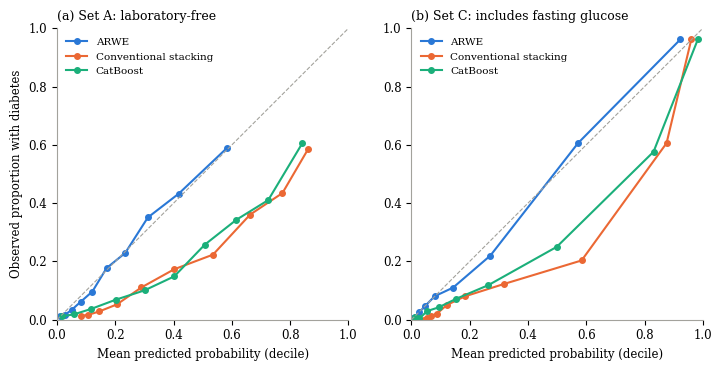

In [10]:
def cal_int_slope(y, p):
    z = logit(p); slope = LogisticRegression(C=1e6, max_iter=2000).fit(z.reshape(-1, 1), y).coef_[0][0]
    a = minimize_scalar(lambda a: np.sum(np.logaddexp(0, z + a)) - np.sum(y * (z + a)), bounds=(-10, 10), method="bounded").x
    return a, slope
def pooled(s, r):   # pooled out-of-fold predictions of repeat r
    ii = np.concatenate(ENS[s]["idx"][5*r:5*r+5]); return ENS[s]["y"][ii], {n: np.concatenate(ENS[s]["preds"][n][5*r:5*r+5]) for n in MODELS}, ENS[s]["rows"][ii]
calib = []
for s in SETS:
    for n in MODELS:
        v = np.mean([[*cal_int_slope(y, P[n]), ece(y, P[n])] for y, P, _ in (pooled(s, r) for r in range(N_REPEATS))], 0)
        calib.append({"Data": s, "Model": n, "intercept": v[0], "slope": v[1], "ECE": v[2]})
calib = pd.DataFrame(calib).round(3); display(calib[calib.Data.isin(["A", "C"])])

fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.6))
for ax, s, t in zip(axes, ["A", "C"], ["(a) Set A: laboratory-free", "(b) Set C: includes fasting glucose"]):
    y, P, _ = pooled(s, 0)
    for n, c in [("ARWE", BLUE), ("Conventional stacking", ORANGE), ("CatBoost", GREEN)]:
        p = P[n]; q = np.quantile(p, np.linspace(0, 1, 11)); b = np.clip(np.searchsorted(q, p, side="right") - 1, 0, 9)
        ax.plot([p[b == i].mean() for i in range(10)], [y[b == i].mean() for i in range(10)], "-o", color=c, ms=4, label=n)
    ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=0.8); ax.set_aspect("equal"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_title(t, loc="left", fontsize=9); ax.set_xlabel("Mean predicted probability (decile)"); ax.legend(frameon=False, fontsize=7.5)
axes[0].set_ylabel("Observed proportion with diabetes"); plt.tight_layout(); plt.savefig(f"{FIGURES}/fig_calibration.png", dpi=300); plt.show()

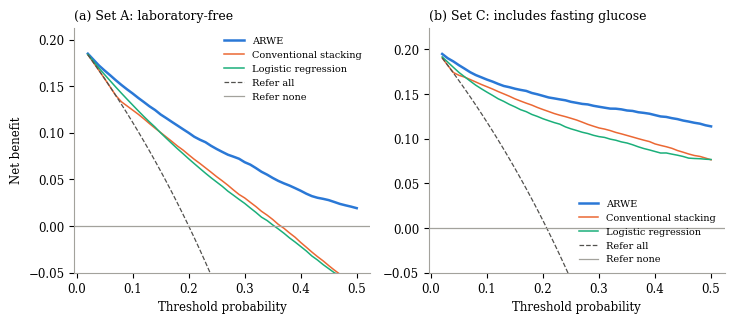

,Set,Risk threshold,Sensitivity,Specificity,PPV,NPV,Flagged
0,A,0.1,0.940,0.484,0.313,0.970,0.601
1,A,0.2,0.799,0.701,0.400,0.933,0.399
2,B,0.1,0.940,0.513,0.326,0.972,0.577
3,B,0.2,0.797,0.717,0.413,0.934,0.386
4,C,0.1,0.920,0.727,0.468,0.972,0.407
5,C,0.2,0.852,0.859,0.611,0.957,0.288
6,D,0.1,0.945,0.467,0.316,0.971,0.618
7,D,0.2,0.795,0.678,0.391,0.927,0.420


In [11]:
def net_benefit(y, p, t): n = len(y); return ((p >= t) & (y == 1)).sum() / n - ((p >= t) & (y == 0)).sum() / n * t / (1 - t)
TS = np.arange(0.02, 0.51, 0.01); DCA = {}
for s in ["A", "B", "C", "D"]:
    DCA[s] = {n: np.mean([[net_benefit(y, P[n], t) for t in TS] for y, P, _ in (pooled(s, r) for r in range(N_REPEATS))], 0)
              for n in ["ARWE", "Calibrated stacking", "Conventional stacking", "Logistic regression"]}
    prev = ENS[s]["y"].mean(); DCA[s]["Refer all"] = prev - (1 - prev) * TS / (1 - TS)
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.3))
for ax, s, t in zip(axes, ["A", "C"], ["(a) Set A: laboratory-free", "(b) Set C: includes fasting glucose"]):
    for n, c, lw in [("ARWE", BLUE, 1.8), ("Conventional stacking", ORANGE, 1.1), ("Logistic regression", GREEN, 1.1)]: ax.plot(TS, DCA[s][n], color=c, lw=lw, label=n)
    ax.plot(TS, DCA[s]["Refer all"], color="#52514e", ls="--", lw=0.9, label="Refer all"); ax.axhline(0, color=GREY, lw=0.9, label="Refer none")
    ax.set_ylim(-0.05, DCA[s]["ARWE"].max() * 1.15); ax.set_title(t, loc="left", fontsize=9); ax.set_xlabel("Threshold probability"); ax.legend(frameon=False, fontsize=7)
axes[0].set_ylabel("Net benefit"); plt.tight_layout(); plt.savefig(f"{FIGURES}/fig_dca.png", dpi=300); plt.show()

thr_rows = []
for s in ["A", "B", "C", "D"]:
    for t in (0.10, 0.20):
        v = []
        for y, P, _ in (pooled(s, r) for r in range(N_REPEATS)):
            yp = P["ARWE"] >= t; tp = (yp & (y == 1)).sum(); fp = (yp & (y == 0)).sum(); fn = (~yp & (y == 1)).sum(); tn = (~yp & (y == 0)).sum()
            v.append([tp/(tp+fn), tn/(tn+fp), tp/(tp+fp), tn/(tn+fn), yp.mean()])
        thr_rows.append({"Set": s, "Risk threshold": t, **dict(zip(["Sensitivity", "Specificity", "PPV", "NPV", "Flagged"], np.mean(v, 0)))})
pd.DataFrame(thr_rows).round(3)

## 8. Robustness: rank stability, subgroups and survey-weighted AUC

In [12]:
rank1 = pd.DataFrame({s: pd.Series([max(MODELS, key=lambda n: ENS[s]["res"][n][i]["AUC"]) for i in range(R)]).value_counts() for s in SETS}).fillna(0).astype(int)
print("Number of folds (of", R, ") in which each model had the highest AUC:"); display(rank1)
sub_rows = []
for s in ["A", "C"]:
    wcol = "WTMEC2YR" if s == "A" else "WTSAF2YR"
    acc = {}
    for y, P, rows in (pooled(s, r) for r in range(N_REPEATS)):
        info = nh.loc[rows]
        groups = {"Female": info.Male == 0, "Male": info.Male == 1, "Age 20-44": info.Age < 45, "Age 45-64": (info.Age >= 45) & (info.Age < 65),
                  "Age >=65": info.Age >= 65, "Mexican American": info.Ethnicity == 1, "Other Hispanic": info.Ethnicity == 2,
                  "Non-Hispanic White": info.Ethnicity == 3, "Non-Hispanic Black": info.Ethnicity == 4, "Non-Hispanic Asian": info.Ethnicity == 6,
                  "Other/multiracial": info.Ethnicity == 7}
        for g, m in groups.items():
            m = m.values; acc.setdefault(g, []).append((roc_auc_score(y[m], P["ARWE"][m]), roc_auc_score(y[m], P["Logistic regression"][m]), m.sum(), y[m].sum()))
        w = info[wcol].values; ok = w > 0
        acc.setdefault("Survey-weighted (all)", []).append((roc_auc_score(y[ok], P["ARWE"][ok], sample_weight=w[ok]),
                                                            roc_auc_score(y[ok], P["Logistic regression"][ok], sample_weight=w[ok]), ok.sum(), y[ok].sum()))
        acc.setdefault("Unweighted (all)", []).append((roc_auc_score(y, P["ARWE"]), roc_auc_score(y, P["Logistic regression"]), len(y), y.sum()))
    for g, v in acc.items():
        v = np.array(v); sub_rows.append({"Set": s, "Subgroup": g, "n": int(v[0, 2]), "cases": int(v[0, 3]), "ARWE AUC": v[:, 0].mean(), "LR AUC": v[:, 1].mean()})
pd.DataFrame(sub_rows).round(3)

Number of folds (of 25 ) in which each model had the highest AUC:


,A,B,C,D,PIMA
ARWE,7,5,10,1,5
Calibrated stacking,3,9,4,5,5
CatBoost,3,5,2,0,5
Conventional stacking,4,2,2,3,3
Extra Trees,0,0,0,2,3
Logistic regression,2,0,1,10,3
Soft voting,5,1,1,2,0
Weighted soft voting,1,3,5,2,1


,Set,Subgroup,n,cases,ARWE AUC,LR AUC
0,A,Female,2553,468,0.819,0.816
1,A,Male,2414,526,0.831,0.828
2,A,Age 20-44,1810,95,0.799,0.804
3,A,Age 45-64,1826,432,0.768,0.769
4,A,Age >=65,1331,467,0.743,0.735
5,A,Mexican American,671,151,0.818,0.813
6,A,Other Hispanic,474,92,0.802,0.806
7,A,Non-Hispanic White,1732,313,0.827,0.822
8,A,Non-Hispanic Black,1138,239,0.829,0.826
9,A,Non-Hispanic Asian,699,143,0.819,0.820


## 9. Frankfurt Hospital file: integrity audit
Checks exact duplicates, label conflicts, exact overlap with Pima (all 8 predictors + outcome), unmatched records, rounding/encoding,
then compares **random CV on the original file**, **random CV after de-duplication** and **grouped CV** (identical predictor vectors kept in the same fold).
Wording in the manuscript is deliberately cautious: the data show *exact record overlap* and *duplicate contamination*; provenance cannot be established.

In [14]:
F8 = PC[:-1]
fr = pd.read_csv(f"{DATA}/frankfurt_diabetes.csv"); fr.columns = PC
fu = fr.drop_duplicates(); freq = fr.groupby(PC).size()
p2 = pima_raw.reset_index().rename(columns={"index": "pima_id"}); m = fu.merge(p2, on=PC, how="left")
audit = {"rows": len(fr), "exact_duplicate_rows": int(fr.duplicated().sum()), "unique_rows": len(fu),
         "unique_predictor_vectors": int(fr[F8].drop_duplicates().shape[0]), "max_copies": int(freq.max()),
         "copy_frequency": freq.value_counts().sort_index().to_dict(),
         "label_conflicts": int((fr.groupby(F8).Outcome.nunique() > 1).sum()),
         "unique_rows_matching_pima": int(m.pima_id.notna().sum()), "distinct_pima_records_matched": int(m.pima_id.nunique()),
         "raw_rows_matching_pima": int(fr.merge(pima_raw, on=PC).shape[0]),
         "positives_raw": f"{fr.Outcome.mean():.3f}", "positives_unique": f"{fu.Outcome.mean():.3f}"}
for k, v in audit.items(): print(f"{k:32s} {v}")
un = m[m.pima_id.isna()][PC]; P8 = pima_raw[F8].values.astype(float); sd = P8.std(0)
un = un.assign(fields_differing_from_nearest_pima=[int((P8[np.abs((P8 - r) / sd).sum(1).argmin()] != r).sum()) for r in un[F8].values.astype(float)])
print("\nUnmatched records:"); display(un)

rows                             2000
exact_duplicate_rows             1256
unique_rows                      744
unique_predictor_vectors         744
max_copies                       6
copy_frequency                   {1: 14, 2: 272, 3: 404, 4: 41, 5: 12, 6: 1}
label_conflicts                  0
unique_rows_matching_pima        734
distinct_pima_records_matched    734
raw_rows_matching_pima           1981
positives_raw                    0.342
positives_unique                 0.340

Unmatched records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,fields_differing_from_nearest_pima
0,2,138,62,35,0,33.6,0.127,47,1,7
735,0,136,74,49,220,20.1,0.820,44,1,7
736,0,116,64,39,225,40.2,0.720,50,0,7
737,2,142,94,59,177,38.3,0.620,63,1,8
738,4,183,66,0,215,80.6,0.654,40,0,8
739,1,100,62,0,0,64.4,0.152,36,0,5
740,0,163,40,23,64,40.7,0.322,33,0,7
741,6,139,84,37,0,50.7,0.320,50,1,7
742,2,167,44,30,140,52.7,0.452,28,0,7
743,3,162,0,110,215,48.7,0.520,24,0,7


Random CV: 91.2% of test rows (range 86.0%-94.8%) have an identical copy in the training fold


,"Random CV, original","Random CV, de-duplicated","Grouped CV, original",Acc. random,Acc. grouped,Acc. 70/30 hold-out
Logistic regression,0.834 ± 0.017,0.827 ± 0.031,0.829 ± 0.032,0.779,0.771,0.781
k-NN (k=5),0.897 ± 0.014,0.773 ± 0.039,0.723 ± 0.041,0.801,0.715,0.797
Random Forest,0.996 ± 0.005,0.823 ± 0.030,0.817 ± 0.038,0.976,0.751,0.965
Extra Trees,0.998 ± 0.001,0.819 ± 0.030,0.819 ± 0.034,0.976,0.760,0.967
CatBoost,0.980 ± 0.010,0.829 ± 0.029,0.818 ± 0.038,0.941,0.754,0.932


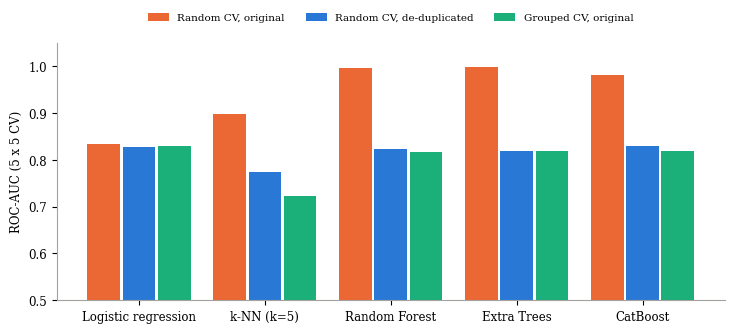

In [15]:
groups = fr.groupby(F8, sort=False).ngroup().values
FM = {"Logistic regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
      "k-NN (k=5)": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
      "Random Forest": lambda: RandomForestClassifier(500, random_state=0, n_jobs=2),
      "Extra Trees": lambda: ExtraTreesClassifier(500, random_state=0, n_jobs=2),
      "CatBoost": lambda: CatBoostClassifier(iterations=500, verbose=0, random_seed=0, thread_count=2)}
def cv_scores(X, y, splits):
    out = {k: {"auc": [], "acc": []} for k in FM}
    for tr, te in splits:
        for k, mk in FM.items():
            p = mk().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
            out[k]["auc"].append(roc_auc_score(y[te], p)); out[k]["acc"].append(accuracy_score(y[te], (p >= .5).astype(int)))
    return out
Xf, yf = fr[F8].values, fr.Outcome.values; Xu, yu = fu.reset_index(drop=True)[F8].values, fu.reset_index(drop=True).Outcome.values
rand = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(Xf, yf))
share = [np.isin(groups[te], groups[tr]).mean() for tr, te in rand]
print(f"Random CV: {np.mean(share):.1%} of test rows (range {min(share):.1%}-{max(share):.1%}) have an identical copy in the training fold")
FCV = {"random_raw": cv_scores(Xf, yf, rand),
       "random_dedup": cv_scores(Xu, yu, RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(Xu, yu)),
       "grouped_raw": cv_scores(Xf, yf, [sp for r in range(5) for sp in StratifiedGroupKFold(5, shuffle=True, random_state=r).split(Xf, yf, groups)])}
hold = {k: [] for k in FM}                       # 70/30 random hold-out, as in single-split studies
for sd_ in range(20):
    tr, te = train_test_split(np.arange(len(yf)), test_size=0.3, stratify=yf, random_state=sd_)
    for k, mk in FM.items(): hold[k].append(accuracy_score(yf[te], mk().fit(Xf[tr], yf[tr]).predict(Xf[te])))
NAMES = {"random_raw": "Random CV, original", "random_dedup": "Random CV, de-duplicated", "grouped_raw": "Grouped CV, original"}
fcv = pd.DataFrame({NAMES[sch]: {k: f"{np.mean(v['auc']):.3f} ± {np.std(v['auc'], ddof=1):.3f}" for k, v in r.items()} for sch, r in FCV.items()})
fcv["Acc. random"] = [np.mean(FCV["random_raw"][k]["acc"]) for k in FM]; fcv["Acc. grouped"] = [np.mean(FCV["grouped_raw"][k]["acc"]) for k in FM]
fcv["Acc. 70/30 hold-out"] = [np.mean(hold[k]) for k in FM]; display(fcv.round(3))
x = np.arange(len(FM)); fig, ax = plt.subplots(figsize=(7.4, 3.4))
for i, (sch, c) in enumerate(zip(FCV, [ORANGE, BLUE, GREEN])):
    mm = [np.mean(FCV[sch][k]["auc"]) for k in FM]; ax.bar(x + (i - 1) * 0.28, mm, 0.26, color=c, label=NAMES[sch])
ax.set_xticks(x); ax.set_xticklabels(FM); ax.set_ylim(0.5, 1.05); ax.set_ylabel("ROC-AUC (5 x 5 CV)")
ax.legend(frameon=False, fontsize=7.5, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.15))
plt.tight_layout(); plt.savefig(f"{FIGURES}/fig_frankfurt_cv.png", dpi=300); plt.show()

## 10. Permutation importance (stacking ensemble, stratified 20 % hold-out)

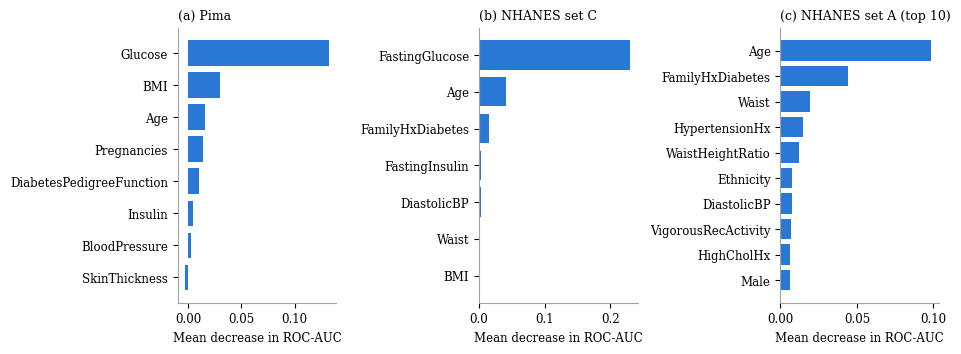

In [16]:
def stack_model(cols):
    base = [(k, make_pipeline(preprocessor(cols), m)) for k, m in learners().items()]
    return StackingClassifier(base, final_estimator=LogisticRegression(class_weight="balanced", max_iter=2000), cv=5, stack_method="predict_proba")
IMP = {}
for s in ["PIMA", "C", "A"]:
    cols, dd, _ = SETS[s]; Xtr, Xte, ytr, yte = train_test_split(dd[cols], dd.Diabetes.values, test_size=0.2, stratify=dd.Diabetes.values, random_state=SEED)
    mdl = stack_model(cols).fit(Xtr, ytr)
    pi = permutation_importance(mdl, Xte, yte, scoring="roc_auc", n_repeats=20, random_state=0)
    IMP[s] = pd.Series(pi.importances_mean, index=cols).sort_values()
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.6))
for ax, s, t in zip(axes, ["PIMA", "C", "A"], ["(a) Pima", "(b) NHANES set C", "(c) NHANES set A (top 10)"]):
    v = IMP[s].tail(10); ax.barh(v.index, v.values, color=BLUE); ax.set_title(t, loc="left", fontsize=9); ax.set_xlabel("Mean decrease in ROC-AUC")
plt.tight_layout(); plt.savefig(f"{FIGURES}/fig_importance.png", dpi=300); plt.show()

## 11. Save all results (same file formats used to build the manuscript tables)

In [17]:
conv = lambda o: o.tolist() if isinstance(o, np.ndarray) else (int(o) if isinstance(o, np.integer) else float(o))
for s in SETS:
    E = ENS[s]
    json.dump({"set": s, "n": int(len(E["y"])), "row_index": E["rows"].tolist(), "y": E["y"].tolist(), "results": E["res"], "info": E["info"],
               "preds": {"_idx": [i.tolist() for i in E["idx"]], **{n: [np.round(p, 6).tolist() for p in E["preds"][n]] for n in MODELS}}},
              open(f"{RESULTS}/ensemble_predictions_{s}.json", "w"), default=conv)
best_vs_single.to_csv(f"{RESULTS}/best_ensemble_vs_single.csv", index=False)
calib.to_csv(f"{RESULTS}/calibration.csv", index=False)
pd.DataFrame(thr_rows).to_csv(f"{RESULTS}/risk_thresholds.csv", index=False)
pd.DataFrame(sub_rows).to_csv(f"{RESULTS}/subgroups.csv", index=False)
rank1.to_csv(f"{RESULTS}/rank_stability.csv")
pd.concat({s: table(s) for s in SETS}).to_csv(f"{RESULTS}/main_results_all_sets.csv")
json.dump({"audit": audit, "test_rows_with_copy_in_train": [float(np.mean(share)), float(min(share)), float(max(share))], **FCV, "holdout70_30_raw_acc": hold}, open(f"{RESULTS}/frankfurt_audit_cv.json", "w"), default=conv)
print("saved to", os.path.abspath(RESULTS))

saved to /results
